# Human activity recognition: benchmark evaluation

**Question:** Can smartphone accelerometer and gyroscope summaries distinguish six everyday activities?

Source: [UCI Human Activity Recognition](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones). The dataset's supplied train/test split is preserved for a fair benchmark comparison.

In [1]:
from pathlib import Path
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

root=Path('../datasets/portfolio-expansion/har/data/UCI HAR Dataset')
raw_names = pd.read_csv(root/'features.txt', sep=r'\s+', header=None, names=['id','name']).name
base_names = raw_names.str.replace('[^0-9a-zA-Z_]+', '_', regex=True).tolist()
# Punctuation cleanup can collapse distinct source names; append a suffix only when needed.
seen, features = {}, []
for name in base_names:
    seen[name] = seen.get(name, 0) + 1
    features.append(name if seen[name] == 1 else f'{name}_{seen[name]}')
assert len(features) == len(set(features)) == 561
X_train=pd.read_csv(root/'train/X_train.txt',sep=r'\s+',header=None,names=features)
X_test=pd.read_csv(root/'test/X_test.txt',sep=r'\s+',header=None,names=features)
y_train=pd.read_csv(root/'train/y_train.txt',header=None).iloc[:,0]; y_test=pd.read_csv(root/'test/y_test.txt',header=None).iloc[:,0]
labels=pd.read_csv(root/'activity_labels.txt',sep=r'\s+',header=None,names=['id','activity'])
model=RandomForestClassifier(n_estimators=300,min_samples_leaf=2,n_jobs=-1,random_state=42).fit(X_train,y_train)
prediction=model.predict(X_test)
print(classification_report(y_test,prediction,target_names=labels.activity.tolist()))

                    precision    recall  f1-score   support

           WALKING       0.89      0.97      0.93       496
  WALKING_UPSTAIRS       0.89      0.90      0.89       471
WALKING_DOWNSTAIRS       0.96      0.85      0.90       420
           SITTING       0.93      0.89      0.91       491
          STANDING       0.90      0.94      0.92       532
            LAYING       1.00      1.00      1.00       537

          accuracy                           0.93      2947
         macro avg       0.93      0.92      0.92      2947
      weighted avg       0.93      0.93      0.93      2947



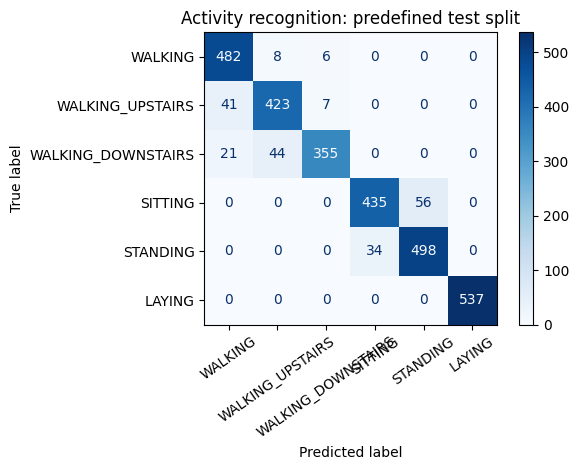

In [2]:
ConfusionMatrixDisplay.from_predictions(y_test,prediction,display_labels=labels.activity,xticks_rotation=35,cmap='Blues')
plt.title('Activity recognition: predefined test split'); plt.tight_layout(); plt.show()
# Keep participants disjoint across train/test; randomising rows would overstate performance.

## Portfolio takeaway

This project demonstrates high-dimensional sensor classification under a supplied benchmark protocol. Next: reduce features for mobile latency and validate on new devices and participants.